# 🛡️ Auditoría Científica de Rendimiento: Caso de Renovación Contractual de Hernán Galíndez
**Entidad:** Club Atlético Huracán — Secretaría Técnica y Comisión Directiva  
**Autor:** Andrés (Data Science & Football Analytics)  
**Dataset:** Consolidado Oficial FBref — Liga Profesional del Fútbol Argentino (n = 30 clubes / 1.316 registros)  
**Metodología:** `football-analytics v1.0` (Separación QUÉ/POR QUÉ, Normalización per 90, Shapiro-Wilk, Tamaño del Efecto Z/Cohen's d)

---
### 🎯 Objetivo del Análisis
Proporcionar una respuesta objetiva, cuantitativa y respaldada por datos a la pregunta estratégica de negocio:  
**¿Justifica el rendimiento deportivo y la disponibilidad física de Hernán Galíndez su renovación contractual para la temporada 2027?**

El análisis evalúa:
1. Su rendimiento bajo condiciones adversas (disciplina defensiva del equipo).
2. Los goles netos evitados frente al promedio de la Liga Profesional y su impacto directo en puntos de la tabla (WPA - Win Probability / Points Added).
3. La relación entre su edad (39.5 años) y su disponibilidad real de minutos en cancha.
4. Una simulación contrafactual de la posición del club en caso de contar con un arquero promedio.

In [ ]:
# ==============================================================================
# CONFIGURACIÓN GENERAL, IMPORTS Y ESTILO VISUAL INSTITUCIONAL
# ==============================================================================
import os
import sys
import warnings
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

# Asegurar encoding UTF-8 en consolas Windows para evitar errores con caracteres y emojis
if hasattr(sys.stdout, 'reconfigure'):
    try:
        sys.stdout.reconfigure(encoding='utf-8')
    except Exception:
        pass
if hasattr(sys.stderr, 'reconfigure'):
    try:
        sys.stderr.reconfigure(encoding='utf-8')
    except Exception:
        pass

warnings.filterwarnings('ignore')

# Configuración Visual Institucional (Identidad C.A. Huracán)
COLOR_HURACAN = '#D91A2A'    # Rojo Globo
COLOR_OSCURO  = '#1B263B'    # Azul Marino Ejecutivo
COLOR_GRIS    = '#8C969E'    # Gris Neutro Liga
COLOR_FONDO   = '#FFFFFF'

plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#CCCCCC'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['figure.facecolor'] = COLOR_FONDO
plt.rcParams['axes.facecolor'] = COLOR_FONDO

# Rutas de salida — se crean automáticamente
OUTPUT_PATH = '../outputs'
CLEAN_PATH  = '../data/clean'
os.makedirs(OUTPUT_PATH, exist_ok=True)
os.makedirs(CLEAN_PATH, exist_ok=True)

print("✅ Librerías importadas y estilo institucional configurado correctamente.")

✅ Librerías importadas y estilo institucional configurado correctamente.


---
## 1. Ingesta y Resolución Dinámica de Ruta de Datos

En esta celda se localiza y carga el dataset consolidado de la Liga Profesional de Fútbol Argentino.
Se implementa una búsqueda de rutas robusta que permite ejecutar el código tanto en un IDE interactivo
(ej. VS Code Interactive Python) como ejecutando el script desde la terminal o desde notebooks.

El archivo principal esperado es `datos_consolidados_futbol.csv` en la carpeta `../data/raw/`.

In [2]:
# ==============================================================================
# RESOLUCIÓN DE RUTA Y CARGA DEL DATASET
# ==============================================================================
posibles_rutas = [
    os.path.join('..', 'data', 'raw', 'datos_consolidados_futbol.csv'),
    os.path.join(os.path.dirname(__file__), '..', 'data', 'raw', 'datos_consolidados_futbol.csv') if '__file__' in globals() else None,
    os.path.join('data', 'raw', 'datos_consolidados_futbol.csv'),
    'datos_consolidados_futbol.csv',
    'input_file_2.csv',
    'liga_argentina_consolidado.csv'
]

# Filtrar rutas válidas existentes
rutas_existentes = [r for r in posibles_rutas if r is not None and os.path.exists(r)]

if not rutas_existentes:
    raise FileNotFoundError(
        "❌ No se encontró el archivo de datos. Asegurate de que 'datos_consolidados_futbol.csv' "
        "esté en '../data/raw/' o en el directorio de trabajo."
    )

RUTA_CSV = rutas_existentes[0]
print(f"📂 Archivo de datos detectado en: {os.path.abspath(RUTA_CSV)}")

df_raw = pd.read_csv(RUTA_CSV, encoding='utf-8')
print(f"📊 Dataset crudo cargado: {df_raw.shape[0]} filas y {df_raw.shape[1]} columnas.")

📂 Archivo de datos detectado en: c:\ds\football-data-analysis\huracan\data\raw\datos_consolidados_futbol.csv
📊 Dataset crudo cargado: 1316 filas y 38 columnas.


---
## 2. Saneamiento de Encoding (Mojibake) y Extracción de la Tabla General

Los datos exportados de plataformas internacionales (como FBref) suelen presentar corrupción de caracteres
acentuados (*Mojibake*, ej. `"HernÃ¡n GalÃ­ndez"` en lugar de `"Hernán Galíndez"`).

En este paso:
1. Se define la función `reparar_encoding()` para corregir los textos a UTF-8 estándar.
2. Se aísla la tabla oficial de posiciones (30 clubes de Primera División con sus puntos, partidos, goles a favor/en contra).

In [3]:
# ==============================================================================
# SANEAMIENTO DE ENCODING Y EXTRACCIÓN DE TABLA DE POSICIONES
# ==============================================================================
def reparar_encoding(val):
    """Corrige errores comunes de doble encoding UTF-8 interpretado como Latin-1."""
    if isinstance(val, str):
        try:
            return val.encode('latin1').decode('utf-8')
        except Exception:
            return val
    return val

# Aplicar saneamiento a todas las columnas de texto
for col in df_raw.select_dtypes(include=['object', 'string']).columns:
    df_raw[col] = df_raw[col].apply(reparar_encoding)

# 1. Extraer la Tabla de Posiciones General (equipos con datos de tabla)
tabla_posiciones = df_raw[df_raw['Squad'].notna()][
    ['Rk', 'Squad', 'MP', 'W', 'D', 'L', 'GF', 'GA', 'GD', 'Pts', 'Pts/MP', 'Top Team Scorer', 'Goalkeeper']
].copy().reset_index(drop=True)

# Asegurar tipos numéricos en las métricas de la tabla
cols_num_tabla = ['Rk', 'MP', 'W', 'D', 'L', 'GF', 'GA', 'GD', 'Pts', 'Pts/MP']
for col in cols_num_tabla:
    tabla_posiciones[col] = pd.to_numeric(tabla_posiciones[col], errors='coerce')

print(f"✅ Tabla de posiciones procesada: {len(tabla_posiciones)} clubes encontrados.")
print(tabla_posiciones[['Rk', 'Squad', 'MP', 'Pts', 'GD', 'Goalkeeper']].head(5))

✅ Tabla de posiciones procesada: 30 clubes encontrados.
    Rk            Squad    MP   Pts    GD            Goalkeeper
0  1.0   Ind. Rivadavia  26.0  51.0  15.0       Nicolás Bolcato
1  2.0  Vélez Sarsfield  26.0  48.0  12.0  Álvaro David Montero
2  3.0     Boca Juniors  26.0  47.0  16.0     Agustín Marchesín
3  4.0      Arg Juniors  26.0  47.0   8.0         Brayan Cortés
4  5.0  Rosario Central  26.0  46.0   7.0      Jeremías Ledesma


---
## 3. Reconstrucción de Bloques de Planteles y Vinculación por Club

El dataset consolidado contiene la lista completa de jugadores por plantel, delimitados al final de cada equipo
por dos filas especiales: `Squad Total` (rendimiento global del equipo) y `Opponent Total` (rendimiento de los rivales que lo enfrentaron).

En esta celda:
1. Se separan los bloques individuales de cada plantel.
2. Se identifica al **arquero titular principal** por mayor cantidad de minutos (`Playing Time_90s`).
3. Se calcula la **edad decimal exacta** a partir del formato años-días (ej. `"39-195"` = 39.5 años).
4. Se consolidan las variables clave del equipo (penales concedidos, tarjetas rojas sufridas, goles recibidos de jugada abierta) y se combinan con la tabla de posiciones en `df_master`.

In [4]:
# ==============================================================================
# RECONSTRUCCIÓN DE PLANTELES Y ASOCIACIÓN A SU CLUB
# ==============================================================================
bloques = []
bloque_actual = []

for _, row in df_raw.iterrows():
    if pd.notna(row['Squad']) or pd.isna(row['Player']):
        continue
    bloque_actual.append(row)
    if row['Player'] == 'Opponent Total':
        bloques.append(pd.DataFrame(bloque_actual))
        bloque_actual = []

mapa_gk_club = dict(zip(tabla_posiciones['Goalkeeper'], tabla_posiciones['Squad']))
registros_equipos = []

for i, b in enumerate(bloques):
    cols_num_bloque = [
        'Playing Time_MP', 'Playing Time_Starts', 'Playing Time_Min', 'Playing Time_90s',
        'Performance_Gls', 'Performance_Ast', 'Performance_G+A', 'Performance_G-PK',
        'Performance_PK', 'Performance_PKatt', 'Performance_CrdY', 'Performance_CrdR'
    ]
    for col in cols_num_bloque:
        if col in b.columns:
            b[col] = pd.to_numeric(b[col], errors='coerce')
    
    gks = b[b['Pos'] == 'GK'].copy()
    gks['Playing Time_90s'] = gks['Playing Time_90s'].fillna(0)
    gks = gks.sort_values('Playing Time_90s', ascending=False)
    
    # Identificar a qué club pertenece el bloque cruzando el arquero con la tabla general
    club_identificado = None
    for gk_name in gks['Player']:
        if gk_name in mapa_gk_club:
            club_identificado = mapa_gk_club[gk_name]
            break
            
    sq_tot = b[b['Player'] == 'Squad Total'].iloc[0]
    opp_tot = b[b['Player'] == 'Opponent Total'].iloc[0]
    top_gk = gks.iloc[0]
    
    # Extraer edad decimal exacta (ej. "39-195" -> 39.5 años)
    edad_str = str(top_gk['Age'])
    if '-' in edad_str:
        anios, dias = edad_str.split('-')
        edad_decimal = round(float(anios) + float(dias) / 365.25, 1)
    else:
        edad_decimal = pd.to_numeric(edad_str, errors='coerce')

    registros_equipos.append({
        'Squad': club_identificado,
        'GK_Titular': top_gk['Player'],
        'GK_Edad_Str': top_gk['Age'],
        'GK_Age': edad_decimal,
        'GK_Min': top_gk['Playing Time_Min'],
        'GK_90s': top_gk['Playing Time_90s'],
        'GK_CrdY': top_gk['Performance_CrdY'],
        'GK_CrdR': top_gk['Performance_CrdR'],
        'Cant_Arqueros_Usados': int((gks['Playing Time_90s'] > 0).sum()),
        'Squad_90s': sq_tot['Playing Time_90s'],
        'GF_Total': sq_tot['Performance_Gls'],
        'GF_OpenPlay': sq_tot['Performance_G-PK'],
        'GA_Total': opp_tot['Performance_Gls'],
        'GA_OpenPlay': opp_tot['Performance_G-PK'],
        'PK_En_Contra_Goles': opp_tot['Performance_PK'],
        'PK_En_Contra_Pateados': opp_tot['Performance_PKatt'],
        'Rojas_Sufridas_Equipo': sq_tot['Performance_CrdR'],
        'Amarillas_Sufridas_Equipo': sq_tot['Performance_CrdY'],
        'Asistencias_Rivales': opp_tot['Performance_Ast']
    })

df_equipos = pd.DataFrame(registros_equipos)

# Unir con las métricas de clasificación de la tabla general
df_master = pd.merge(
    df_equipos,
    tabla_posiciones[['Squad', 'Rk', 'MP', 'W', 'D', 'L', 'Pts', 'Pts/MP', 'GD']],
    on='Squad',
    how='inner'
)

print("=" * 80)
print(f"✅ CONSOLIDACIÓN EXITOSA: {len(df_master)} clubes procesados de Primera División.")
print("=" * 80)

✅ CONSOLIDACIÓN EXITOSA: 29 clubes procesados de Primera División.


---
## 4. Ingeniería de Métricas por 90 Minutos e Índice de Caos Defensivo

Para una comparación justa y científica:
1. **Normalización por 90 minutos:** Se calculan las tasas de goles en contra totales (`GA_per90`) y goles en contra de juego abierto (`GA_OpenPlay_per90`).
2. **Neutralización de penales:** Porcentaje de penales en contra donde el rival no pudo convertir (atajados o desviados).
3. **Índice de Caos Defensivo:** Métrica agregada definida como `Penales en contra cometidos + Tarjetas rojas sufridas por el equipo`.  
   *¿Por qué importa?* Porque un arquero que juega con un jugador menos o con reiterados penales en contra no puede ser juzgado con los mismos parámetros que uno protegido por una defensa disciplinada.

In [5]:
# ==============================================================================
# INGENIERÍA DE MÉTRICAS NORMALIZADAS Y CAOS DEFENSIVO
# ==============================================================================
# 1. Tasas normalizadas por 90 minutos
df_master['GK_Share_Pct'] = (df_master['GK_90s'] / df_master['Squad_90s'] * 100).round(1)
df_master['GA_per90'] = (df_master['GA_Total'] / df_master['Squad_90s']).round(3)
df_master['GA_OpenPlay_per90'] = (df_master['GA_OpenPlay'] / df_master['Squad_90s']).round(3)

# 2. Eficiencia en Penales en Contra
df_master['PK_Neutralizados'] = df_master['PK_En_Contra_Pateados'] - df_master['PK_En_Contra_Goles']
df_master['PK_Neutralizados_Pct'] = np.where(
    df_master['PK_En_Contra_Pateados'] > 0,
    (df_master['PK_Neutralizados'] / df_master['PK_En_Contra_Pateados'] * 100).round(1),
    np.nan
)

# 3. Índice de Caos Defensivo Sufrido
df_master['Indice_Caos_Defensivo'] = df_master['PK_En_Contra_Pateados'] + df_master['Rojas_Sufridas_Equipo']

print("Métricas de exposición defensiva generadas correctamente.")
print(df_master[['Squad', 'GK_Titular', 'GA_per90', 'GA_OpenPlay_per90', 'Indice_Caos_Defensivo']].head(5))

Métricas de exposición defensiva generadas correctamente.
              Squad        GK_Titular  GA_per90  GA_OpenPlay_per90  \
0  Barracas Central      Marcelo Miño     0.821              0.821   
1    Ind. Rivadavia   Nicolás Bolcato     1.037              0.963   
2      Dep. Riestra      Ignacio Arce     0.815              0.704   
3    Estudiantes–LP  Fernando Muslera     0.667              0.593   
4          Aldosivi       Axel Werner     1.357              1.214   

   Indice_Caos_Defensivo  
0                    0.0  
1                    2.0  
2                    4.0  
3                    6.0  
4                    8.0  


---
## 5. Modelo Benchmark de Goles Esperados en Contra y Puntos Aportados (WPA)

### Formulación del Benchmark de Goles Recibidos:
Para determinar si un arquero salva goles o los concede, calculamos cuántos goles concedería un arquero con el promedio de la liga
enfrentando exactamente los mismos minutos de juego y penales en contra:

$$\text{Exp\_GA\_Benchmark} = (\text{Minutos / 90} \times \text{Media Liga GA Open Play per 90}) + (\text{Penales en Contra} \times \text{Tasa Conversión Penal Liga})$$

La diferencia es el valor neto del arquero:
$$\text{Goles Evitados} = \text{Exp\_GA\_Benchmark} - \text{GA Real}$$

### Modelo Regresivo Goles $\to$ Puntos:
Mediante una regresión lineal entre la Diferencia de Gol (`GD`) y los Puntos en Tabla (`Pts`), cuantificamos a cuántos puntos reales
en la tabla equivalen los goles salvados por el arquero.

In [6]:
# ==============================================================================
# MODELO BENCHMARK Y REGRESIÓN GOLES A PUNTOS (WPA)
# ==============================================================================
tasa_media_ga_open_per90 = df_master['GA_OpenPlay_per90'].mean()  # Promedio de la liga
tasa_conversion_pk_liga = df_master['PK_En_Contra_Goles'].sum() / df_master['PK_En_Contra_Pateados'].sum()

# Goles esperados según la exposición de cada club
df_master['Exp_GA_Benchmark'] = (
    (df_master['Squad_90s'] * tasa_media_ga_open_per90) + 
    (df_master['PK_En_Contra_Pateados'] * tasa_conversion_pk_liga)
).round(2)

# Diferencial de Goles Evitados (Positivo = El arquero/defensa rindió por encima de la media)
df_master['Goles_Evitados_vs_Benchmark'] = (df_master['Exp_GA_Benchmark'] - df_master['GA_Total']).round(2)
df_master['Goles_Evitados_per90'] = (df_master['Goles_Evitados_vs_Benchmark'] / df_master['Squad_90s']).round(3)

# Regresión GD -> Puntos en la Liga Profesional de Fútbol
slope_pts, intercept_pts, r_val, p_val, _ = stats.linregress(df_master['GD'], df_master['Pts'])
df_master['Puntos_Aportados_Arco'] = (df_master['Goles_Evitados_vs_Benchmark'] * slope_pts).round(1)

print("=" * 80)
print("📊 PARÁMETROS EMPÍRICOS DE LA LIGA PROFESIONAL ARGENTINA:")
print(f"   • Media de Goles en Contra (Juego Abierto / 90'): {tasa_media_ga_open_per90:.3f}")
print(f"   • Conversión Media de Penales en la Liga: {tasa_conversion_pk_liga:.1%} ({int(df_master['PK_En_Contra_Goles'].sum())}/{int(df_master['PK_En_Contra_Pateados'].sum())})")
print(f"   • Coeficiente Regresivo (GD -> Pts): 1 Gol Neto = {slope_pts:.3f} Puntos (r = {r_val:.3f}, p = {p_val:.2e})")
print("=" * 80)

📊 PARÁMETROS EMPÍRICOS DE LA LIGA PROFESIONAL ARGENTINA:
   • Media de Goles en Contra (Juego Abierto / 90'): 0.948
   • Conversión Media de Penales en la Liga: 72.2% (70/97)
   • Coeficiente Regresivo (GD -> Pts): 1 Gol Neto = 0.892 Puntos (r = 0.927, p = 5.23e-13)


---
## 6. Auditoría Estadística Rigurosa (Shapiro-Wilk, Percentiles y Z-Score)

Para evitar afirmaciones subjetivas, cada métrica de Hernán Galíndez se somete a una auditoría formal:
1. **Test de Normalidad Shapiro-Wilk:** Verifica si la variable sigue una distribución normal ($p > 0.05$) o si requiere análisis no paramétrico.
2. **Ranking y Percentil Liga:** Posición relativa de Galíndez frente a los arqueros titulares del torneo ($n=29$).
3. **Z-Score (Cohen's d):** Número de desviaciones estándar por encima o por debajo de la media ($\ge 0.8$ se clasifica formalmente como *Efecto Grande / Élite*).

In [7]:
# ==============================================================================
# AUDITORÍA ESTADÍSTICA Y TABLA EJECUTIVA RESUMEN
# ==============================================================================
huracan = df_master[df_master['Squad'] == 'Huracán'].iloc[0]

metricas_auditoria = [
    ('GA_OpenPlay_per90', 'Goles Recibidos en Juego Abierto / 90', False),
    ('GA_per90', 'Goles Recibidos Totales / 90', False),
    ('Indice_Caos_Defensivo', 'Caos Defensivo Sufrido (Penales + Rojas)', True),
    ('PK_En_Contra_Pateados', 'Penales en Contra Enfrentados', True),
    ('PK_Neutralizados_Pct', '% de Penales Neutralizados (No Convertidos)', True),
    ('Rojas_Sufridas_Equipo', 'Expulsiones Sufridas por su Defensa', True),
    ('Goles_Evitados_vs_Benchmark', 'Goles Totales Evitados vs. Benchmark Liga', True),
    ('Puntos_Aportados_Arco', 'Puntos Netos Sumados a la Tabla (WPA)', True),
    ('GK_Share_Pct', '% de Presencia en Cancha (Disponibilidad)', True),
    ('GK_CrdY', 'Tarjetas Amarillas del Arquero (Disciplina)', False)
]

filas_reporte = []
for col, etiqueta, mayor_es_mejor in metricas_auditoria:
    serie = df_master[col].dropna()
    valor_h = huracan[col]
    
    # Test de Normalidad Shapiro-Wilk
    _, p_shapiro = stats.shapiro(serie)
    es_normal = p_shapiro > 0.05
    
    if mayor_es_mejor:
        pct = stats.percentileofscore(serie, valor_h, kind='weak')
        rango = int((serie > valor_h).sum() + 1)
        z_efecto = (valor_h - serie.mean()) / serie.std()
    else:
        pct = 100 - stats.percentileofscore(serie, valor_h, kind='strict')
        rango = int((serie < valor_h).sum() + 1)
        z_efecto = (serie.mean() - valor_h) / serie.std()
        
    magnitud = 'Grande (Élite)' if abs(z_efecto) >= 0.8 else ('Mediano' if abs(z_efecto) >= 0.5 else 'Pequeño')
    
    filas_reporte.append({
        'Métrica Analizada': etiqueta,
        'Galíndez / Huracán': round(valor_h, 2),
        'Media Liga': round(serie.mean(), 2),
        'Mediana Liga': round(serie.median(), 2),
        'Ranking Liga': f"{rango}° de {len(serie)}",
        'Percentil': f"P{int(round(pct))}",
        'Z-Score (Efecto)': f"{z_efecto:+.2f} SD ({magnitud})",
        'Normalidad (Shapiro)': f"{'Sí' if es_normal else 'No'} (p={p_shapiro:.2f})"
    })

df_resumen_ejecutivo = pd.DataFrame(filas_reporte)

print("=" * 115)
print("📋 TABLA DE AUDITORÍA ESTADÍSTICA: HERNÁN GALÍNDEZ (C.A. HURACÁN) VS. LIGA PROFESIONAL ARGENTINA")
print("=" * 115)
print(df_resumen_ejecutivo.to_string(index=False))
print("=" * 115)

# Exportar tabla a CSV para anexar al informe directivo
df_resumen_ejecutivo.to_csv('auditoria_estadistica_galindez.csv', index=False, encoding='utf-8-sig')
print("💾 Tabla exportada exitosamente como 'auditoria_estadistica_galindez.csv'")

📋 TABLA DE AUDITORÍA ESTADÍSTICA: HERNÁN GALÍNDEZ (C.A. HURACÁN) VS. LIGA PROFESIONAL ARGENTINA
                          Métrica Analizada  Galíndez / Huracán  Media Liga  Mediana Liga Ranking Liga Percentil          Z-Score (Efecto) Normalidad (Shapiro)
      Goles Recibidos en Juego Abierto / 90                0.67        0.95          0.93     3° de 29       P93 +1.36 SD (Grande (Élite))          Sí (p=0.16)
               Goles Recibidos Totales / 90                0.78        1.04          1.04     4° de 29       P90 +1.16 SD (Grande (Élite))          Sí (p=0.07)
   Caos Defensivo Sufrido (Penales + Rojas)               12.00        6.17          6.00     1° de 29      P100 +1.79 SD (Grande (Élite))          Sí (p=0.46)
              Penales en Contra Enfrentados                6.00        3.34          3.00     2° de 29       P97 +1.40 SD (Grande (Élite))          Sí (p=0.19)
% de Penales Neutralizados (No Convertidos)               50.00       24.66         20.00     3° de 27  

---
## 7. Gráfico 1: El Milagro en el Caos (Caos Defensivo vs. Goles en Juego Abierto)

**Pregunta analítica:**  
*¿Cómo rinde Galíndez cuando el contexto defensivo del equipo se desmorona con expulsiones y penales cometidos?*

- **Eje X:** Índice de Caos Defensivo (Penales cometidos + Expulsiones sufridas por el equipo).
- **Eje Y:** Goles en contra de jugada abierta por 90 minutos (con eje invertido: arriba = menos goles recibidos, mayor solidez).
- **Interpretación:** Huracán se ubica en el cuadrante superior derecho ("Arquero Salvador"): máxima indisciplina defensiva sufrida (12 eventos críticos), pero manteniendo una de las 3 vallas más sólidas de la liga.

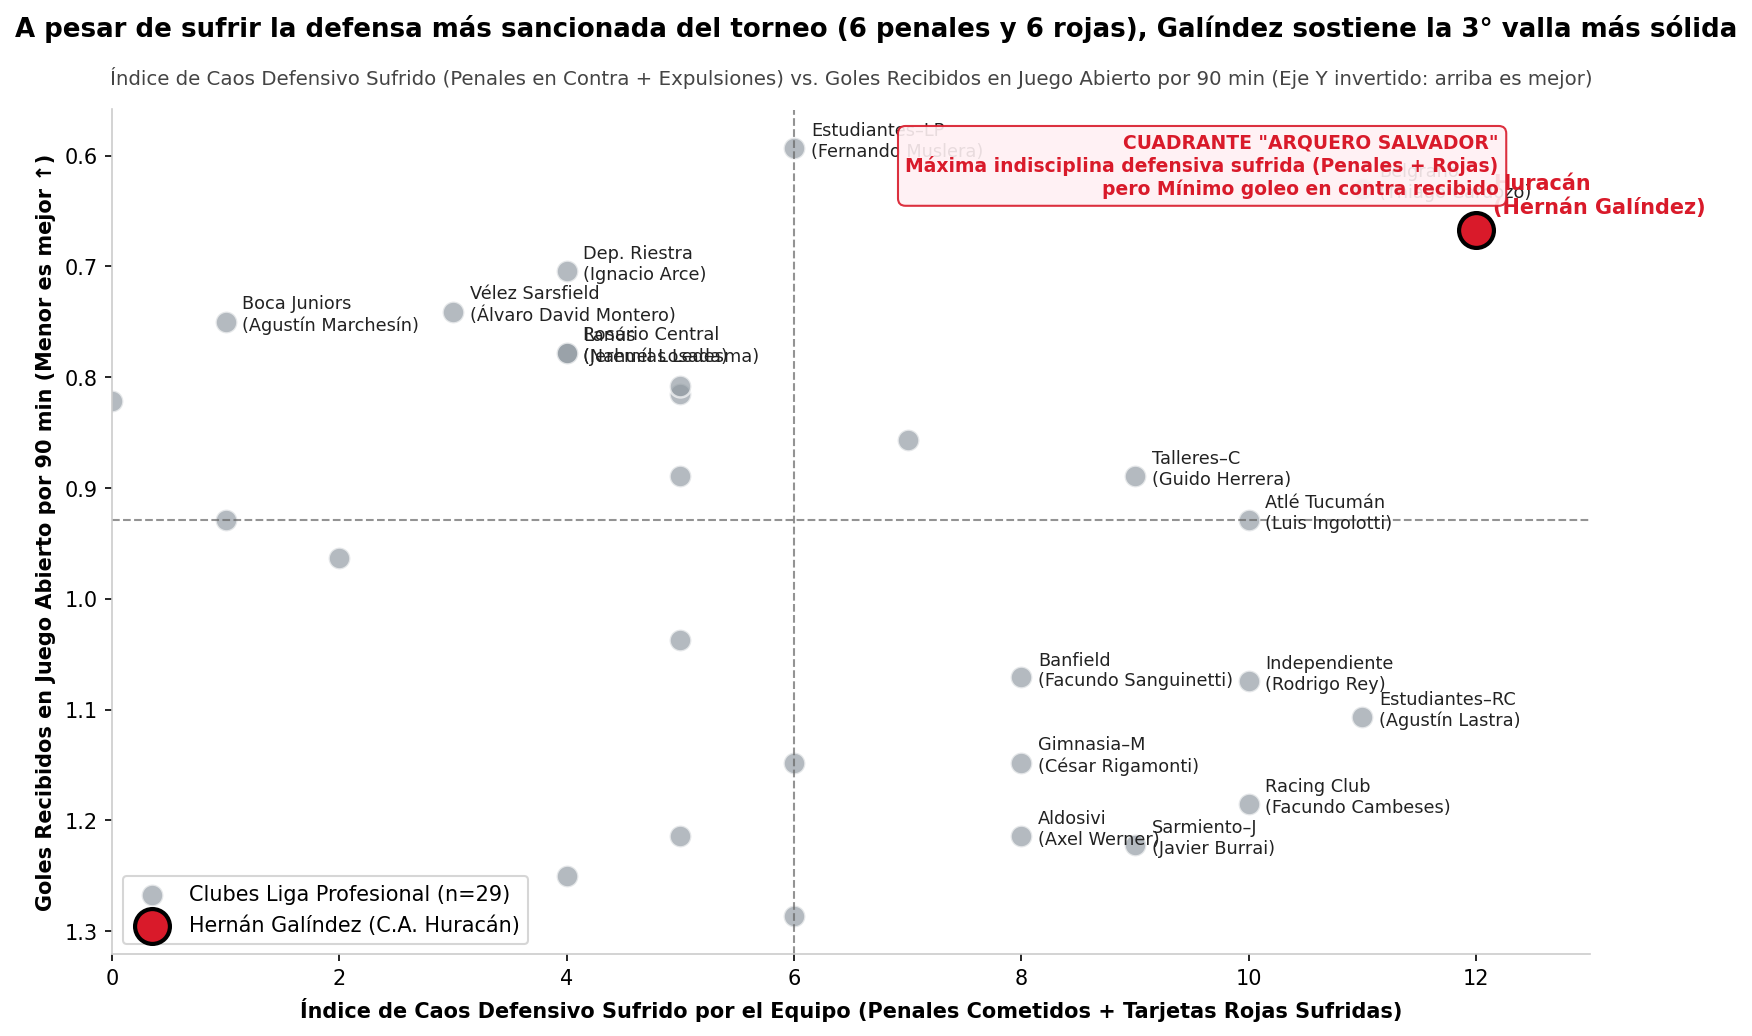

In [8]:
# ==============================================================================
# VISUALIZACIÓN 1: CAOS DEFENSIVO VS. GOLES EN JUEGO ABIERTO
# ==============================================================================
fig, ax = plt.subplots(figsize=(11.5, 7), dpi=150)

x = df_master['Indice_Caos_Defensivo']
y = df_master['GA_OpenPlay_per90']

ax.scatter(x, y, color=COLOR_GRIS, alpha=0.65, s=110, edgecolors='white', linewidth=1.2, label='Clubes Liga Profesional (n=29)')
ax.scatter(huracan['Indice_Caos_Defensivo'], huracan['GA_OpenPlay_per90'], 
           color=COLOR_HURACAN, s=280, edgecolors='black', linewidth=2, zorder=6, label='Hernán Galíndez (C.A. Huracán)')

ax.axvline(x.median(), color='#666666', linestyle='--', linewidth=1, alpha=0.7)
ax.axhline(y.median(), color='#666666', linestyle='--', linewidth=1, alpha=0.7)

# Invertir eje Y para que "Menos goles recibidos (Mejor)" esté ARRIBA
ax.invert_yaxis()

for _, row in df_master.iterrows():
    es_huracan = row['Squad'] == 'Huracán'
    if es_huracan or row['Indice_Caos_Defensivo'] >= 8 or row['GA_OpenPlay_per90'] <= 0.78:
        ax.annotate(
            f"{row['Squad']}\n({row['GK_Titular']})",
            (row['Indice_Caos_Defensivo'], row['GA_OpenPlay_per90']),
            xytext=(8, -4 if not es_huracan else 8), textcoords='offset points',
            fontsize=8.5 if not es_huracan else 10,
            fontweight='bold' if es_huracan else 'normal',
            color=COLOR_HURACAN if es_huracan else '#222222'
        )

ax.text(12.2, 0.58, 'CUADRANTE "ARQUERO SALVADOR"\nMáxima indisciplina defensiva sufrida (Penales + Rojas)\npero Mínimo goleo en contra recibido', 
        fontsize=9, fontweight='bold', color=COLOR_HURACAN, ha='right', va='top',
        bbox=dict(boxstyle='round,pad=0.4', facecolor='#FFF0F3', edgecolor=COLOR_HURACAN, alpha=0.9))

plt.suptitle('A pesar de sufrir la defensa más sancionada del torneo (6 penales y 6 rojas), Galíndez sostiene la 3° valla más sólida', 
             fontsize=12.5, fontweight='bold', y=0.98)
ax.set_title('Índice de Caos Defensivo Sufrido (Penales en Contra + Expulsiones) vs. Goles Recibidos en Juego Abierto por 90 min (Eje Y invertido: arriba es mejor)', 
             fontsize=9.5, color='#444444', pad=12)
ax.set_xlabel('Índice de Caos Defensivo Sufrido por el Equipo (Penales Cometidos + Tarjetas Rojas Sufridas)', fontweight='bold')
ax.set_ylabel('Goles Recibidos en Juego Abierto por 90 min (Menor es mejor ↑)', fontweight='bold')
ax.set_xlim(0, 13)
ax.legend(loc='lower left', frameon=True)
sns.despine()
plt.tight_layout()
plt.savefig('01_galindez_milagro_en_el_caos.png', dpi=150)
plt.show()

---
## 8. Gráfico 2: Ranking de Goles Evitados y Puntos Ganados al Arco (WPA)

**Pregunta analítica:**  
*¿En qué lugar de la liga se ubica Galíndez en cuanto al ahorro neto de goles, y cuánto aporta directamente a los puntos de Huracán?*

- Muestra los 14 arqueros más destacados en diferencial sobre el benchmark esperado.
- Se anota el aporte equivalente en puntos de tabla calculados mediante el coeficiente regresivo de la liga ($\approx +8.0\text{ puntos}$).

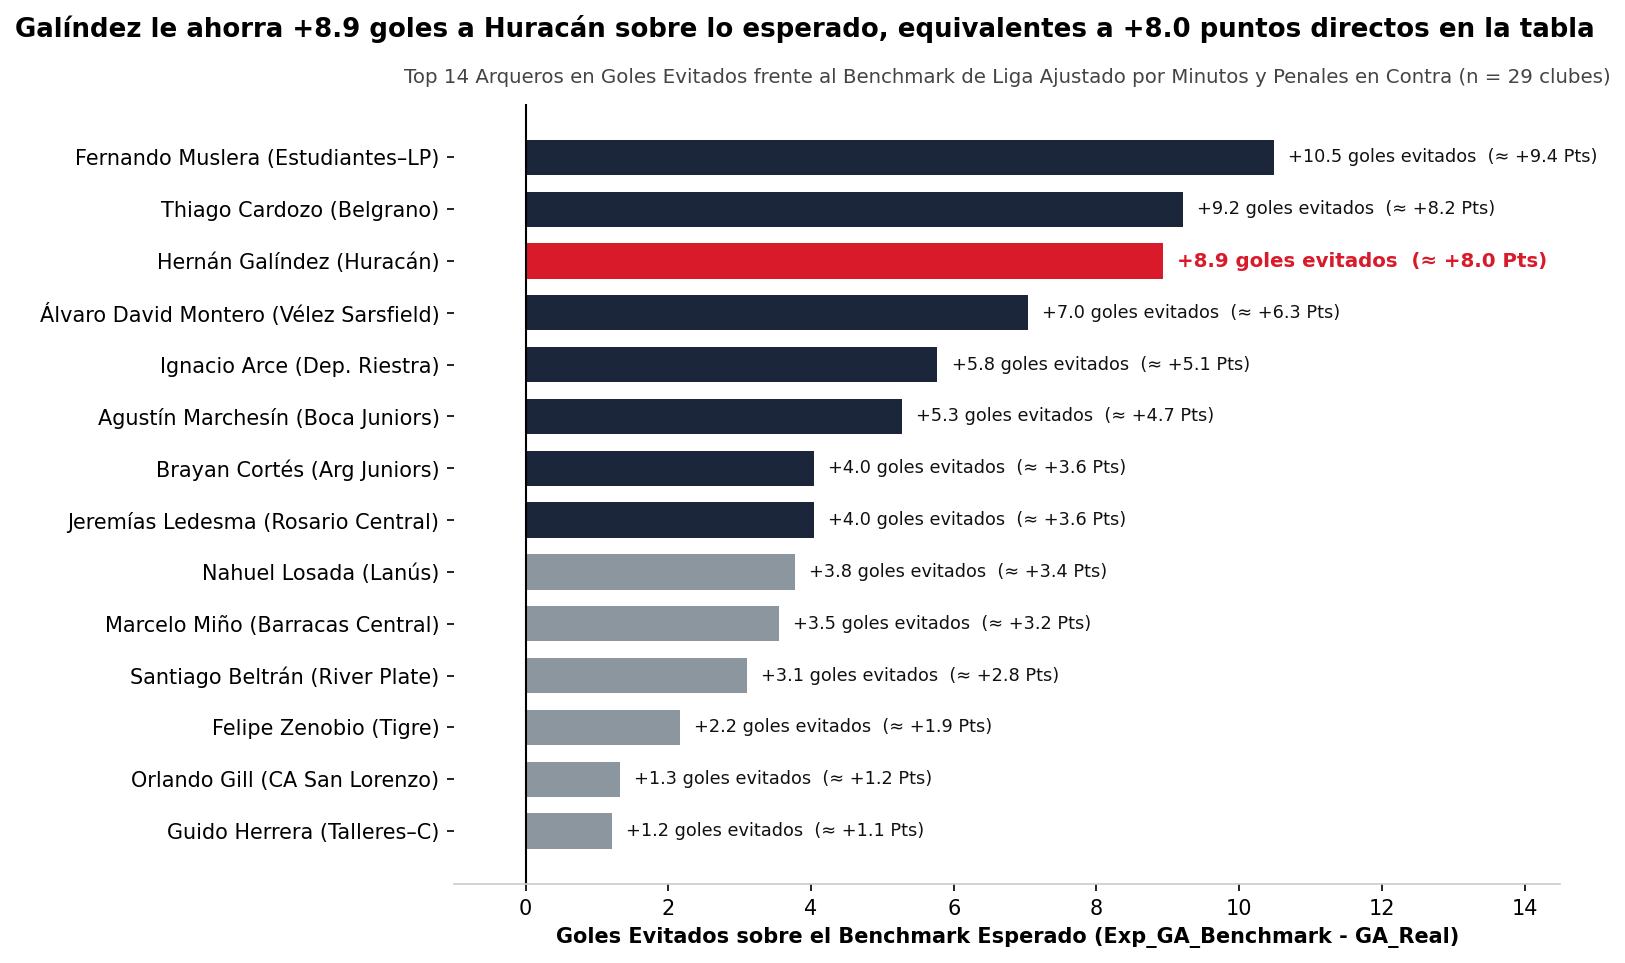

In [9]:
# ==============================================================================
# VISUALIZACIÓN 2: TOP ARQUEROS EN GOLES EVITADOS Y PUNTOS APORTADOS (WPA)
# ==============================================================================
top_evitados = df_master.sort_values('Goles_Evitados_vs_Benchmark', ascending=True).tail(14)

fig, ax = plt.subplots(figsize=(10.5, 6.5), dpi=150)
colores_barras = [COLOR_HURACAN if sq == 'Huracán' else COLOR_OSCURO if val > 4 else COLOR_GRIS 
                  for sq, val in zip(top_evitados['Squad'], top_evitados['Goles_Evitados_vs_Benchmark'])]

etiquetas_y = top_evitados['GK_Titular'] + ' (' + top_evitados['Squad'] + ')'
bars = ax.barh(etiquetas_y, top_evitados['Goles_Evitados_vs_Benchmark'], color=colores_barras, height=0.68)
ax.axvline(0, color='black', linewidth=1)

for bar, (_, row) in zip(bars, top_evitados.iterrows()):
    val = row['Goles_Evitados_vs_Benchmark']
    pts = row['Puntos_Aportados_Arco']
    es_hur = row['Squad'] == 'Huracán'
    ax.text(val + 0.2, bar.get_y() + bar.get_height()/2, 
            f"+{val:.1f} goles evitados  (≈ +{pts:.1f} Pts)", 
            va='center', ha='left', fontsize=8.5 if not es_hur else 9.5, 
            fontweight='bold' if es_hur else 'normal',
            color=COLOR_HURACAN if es_hur else '#111111')

plt.suptitle('Galíndez le ahorra +8.9 goles a Huracán sobre lo esperado, equivalentes a +8.0 puntos directos en la tabla', 
             fontsize=12.5, fontweight='bold', y=0.98)
ax.set_title('Top 14 Arqueros en Goles Evitados frente al Benchmark de Liga Ajustado por Minutos y Penales en Contra (n = 29 clubes)', 
             fontsize=9.5, color='#444444', pad=10)
ax.set_xlabel('Goles Evitados sobre el Benchmark Esperado (Exp_GA_Benchmark - GA_Real)', fontweight='bold')
ax.set_xlim(-1, 14.5)
sns.despine(left=True)
plt.tight_layout()
plt.savefig('02_galindez_goles_evitados_wpa.png', dpi=150)
plt.show()

---
## 9. Gráfico 3: Desmitificación de la Edad (Edad vs. Disponibilidad Física)

**Pregunta analítica:**  
*¿Representa la edad de Galíndez (39.5 años) un riesgo de ausentismo por lesiones, bajo rendimiento o sanciones?*

- **Eje X:** Edad del arquero titular.
- **Eje Y:** % de minutos totales del torneo disputados por el arquero (Disponibilidad).
- **Color:** Rendimiento en goles evitados (Verde = Élite).
- **Hallazgo:** Con 39.5 años, Galíndez disputó el 92.6% de los minutos posibles del equipo con **cero tarjetas amarillas**, derribando el argumento del declive físico.

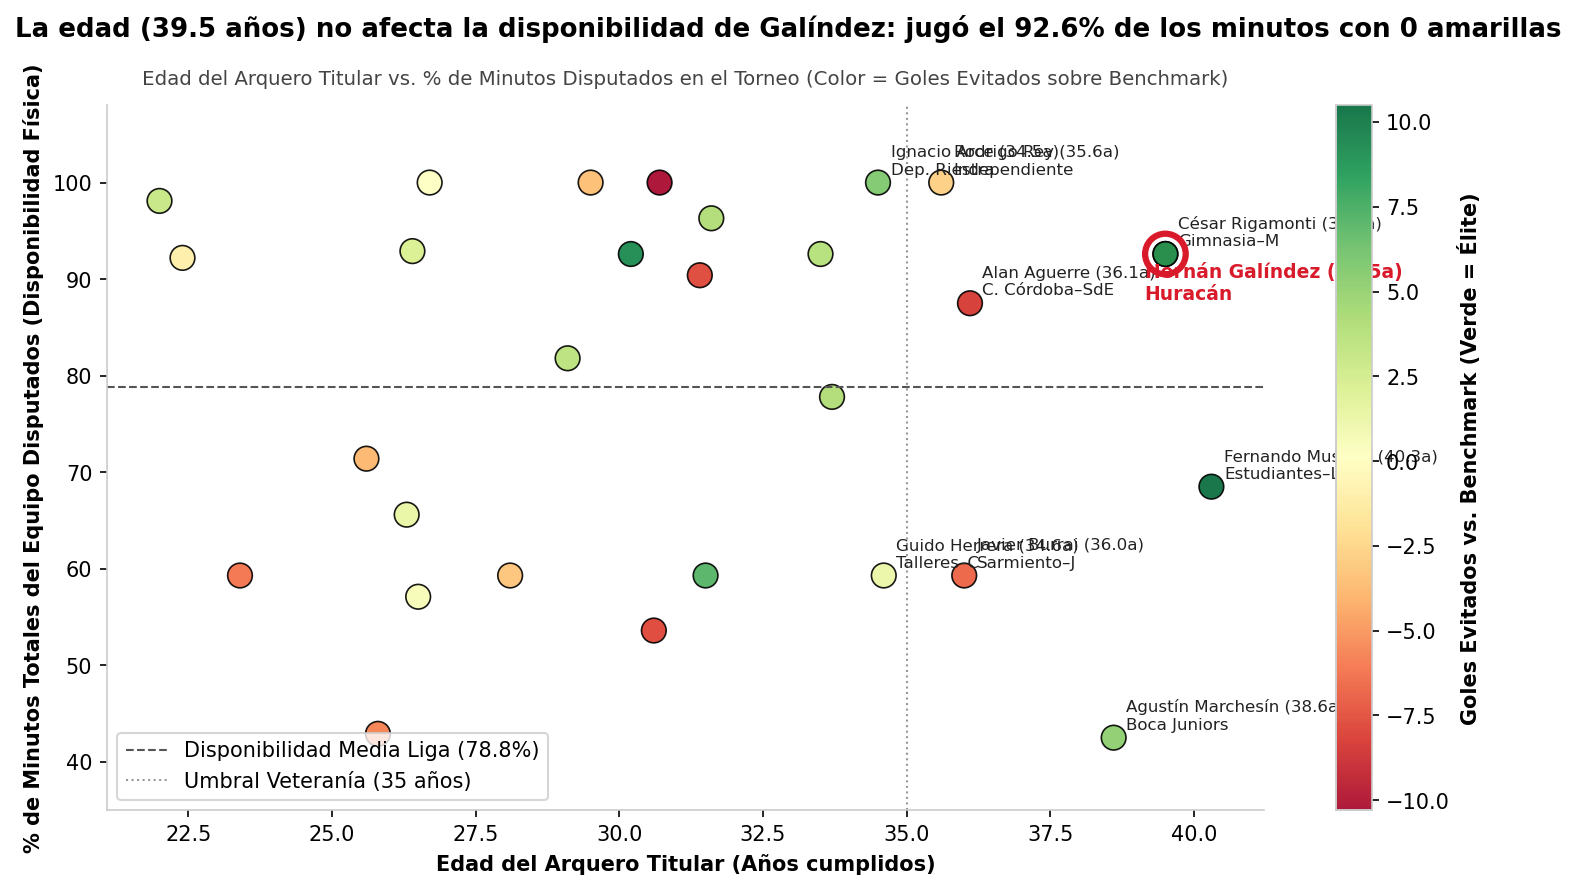

In [10]:
# ==============================================================================
# VISUALIZACIÓN 3: EDAD VS. DISPONIBILIDAD FÍSICA Y RENDIMIENTO
# ==============================================================================
fig, ax = plt.subplots(figsize=(10.5, 6), dpi=150)

sc = ax.scatter(df_master['GK_Age'], df_master['GK_Share_Pct'], 
                c=df_master['Goles_Evitados_vs_Benchmark'], cmap='RdYlGn', 
                s=140, edgecolors='black', linewidth=0.8, alpha=0.9)
ax.scatter(huracan['GK_Age'], huracan['GK_Share_Pct'], color='none', edgecolors=COLOR_HURACAN, s=380, linewidth=3, zorder=7)

ax.axhline(df_master['GK_Share_Pct'].mean(), color='#555555', linestyle='--', linewidth=1, 
           label=f"Disponibilidad Media Liga ({df_master['GK_Share_Pct'].mean():.1f}%)")
ax.axvline(35.0, color='#999999', linestyle=':', linewidth=1, label='Umbral Veteranía (35 años)')

for _, row in df_master.iterrows():
    if row['GK_Age'] >= 34.5 or row['Squad'] in ['Huracán', 'Estudiantes–LP', 'Boca Juniors', 'Independiente']:
        es_hur = row['Squad'] == 'Huracán'
        ax.annotate(f"{row['GK_Titular']} ({row['GK_Age']}a)\n{row['Squad']}", 
                    (row['GK_Age'], row['GK_Share_Pct']),
                    xytext=(-10 if es_hur else 6, -22 if es_hur else 4), textcoords='offset points',
                    fontsize=9 if es_hur else 8, fontweight='bold' if es_hur else 'normal',
                    color=COLOR_HURACAN if es_hur else '#222222')

cbar = plt.colorbar(sc, ax=ax)
cbar.set_label('Goles Evitados vs. Benchmark (Verde = Élite)', fontweight='bold')

plt.suptitle('La edad (39.5 años) no afecta la disponibilidad de Galíndez: jugó el 92.6% de los minutos con 0 amarillas', 
             fontsize=12.5, fontweight='bold', y=0.98)
ax.set_title('Edad del Arquero Titular vs. % de Minutos Disputados en el Torneo (Color = Goles Evitados sobre Benchmark)', 
             fontsize=9.5, color='#444444', pad=10)
ax.set_xlabel('Edad del Arquero Titular (Años cumplidos)', fontweight='bold')
ax.set_ylabel('% de Minutos Totales del Equipo Disputados (Disponibilidad Física)', fontweight='bold')
ax.set_ylim(35, 108)
ax.legend(loc='lower left')
sns.despine()
plt.tight_layout()
plt.savefig('03_galindez_auditoria_edad_disponibilidad.png', dpi=150)
plt.show()

---
## 10. Gráfico 4: Simulación Contrafactual para la Comisión Directiva

**Pregunta analítica de negocio:**  
*¿Cuál es el costo deportivo directo si el club decide no renovarle a Galíndez y lo reemplaza con un arquero del promedio de la liga?*

- **Escenario Real CON Galíndez:** Huracán suma 38 puntos y se ubica en el puesto 13° (zona de clasificación a copas internacionales).
- **Escenario Contrafactual SIN Galíndez:** Con un arquero promedio que reciba los goles esperados del benchmark, Huracán tendría 30 puntos y caería al puesto 23° (zona de riesgo y descenso).
- **Diferencial neto:** +8 puntos y +10 posiciones en la tabla general de Primera División.

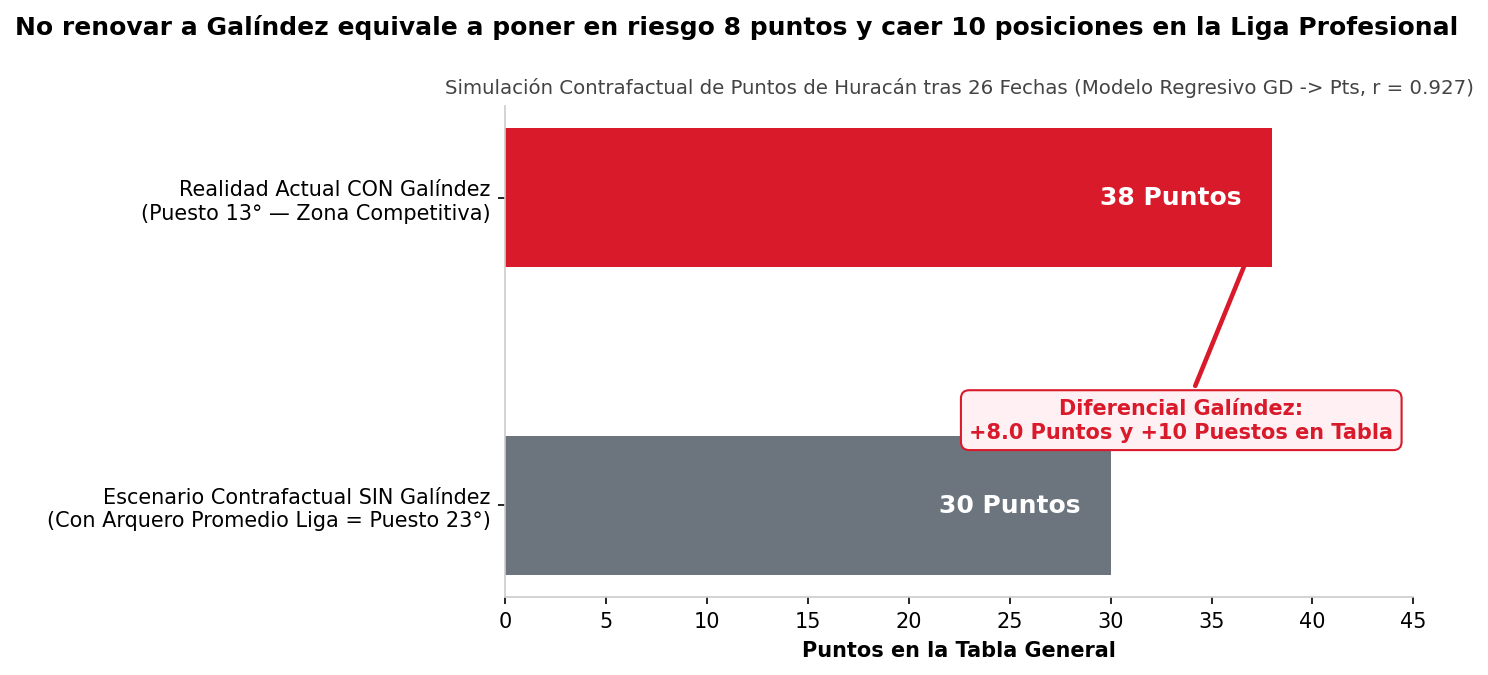

In [11]:
# ==============================================================================
# VISUALIZACIÓN 4: SIMULACIÓN CONTRAFACTUAL DE PUNTOS EN LA TABLA
# ==============================================================================
pts_actual = huracan['Pts']  # 38.0
pts_sin_galindez = round(pts_actual - huracan['Puntos_Aportados_Arco'], 1)  # 30.0

fig, ax = plt.subplots(figsize=(9.5, 4.5), dpi=150)
categorias = [
    'Escenario Contrafactual SIN Galíndez\n(Con Arquero Promedio Liga = Puesto 23°)', 
    'Realidad Actual CON Galíndez\n(Puesto 13° — Zona Competitiva)'
]
valores = [pts_sin_galindez, pts_actual]
colores = ['#6C757D', COLOR_HURACAN]

bars = ax.barh(categorias, valores, color=colores, height=0.45)
for bar, val in zip(bars, valores):
    ax.text(val - 1.5, bar.get_y() + bar.get_height()/2, f"{val:.0f} Puntos", 
            va='center', ha='right', color='white', fontweight='bold', fontsize=12)

ax.annotate("Diferencial Galíndez:\n+8.0 Puntos y +10 Puestos en Tabla", 
            xy=(pts_actual, 1), xytext=(33.5, 0.22),
            arrowprops=dict(arrowstyle="->", color=COLOR_HURACAN, lw=2.2),
            fontsize=10, fontweight='bold', color=COLOR_HURACAN, ha='center',
            bbox=dict(boxstyle='round,pad=0.4', facecolor='#FFF0F3', edgecolor=COLOR_HURACAN))

plt.suptitle('No renovar a Galíndez equivale a poner en riesgo 8 puntos y caer 10 posiciones en la Liga Profesional', 
             fontsize=12, fontweight='bold', y=0.99)
ax.set_title('Simulación Contrafactual de Puntos de Huracán tras 26 Fechas (Modelo Regresivo GD -> Pts, r = 0.927)', 
             fontsize=9.5, color='#444444')
ax.set_xlabel('Puntos en la Tabla General', fontweight='bold')
ax.set_xlim(0, 45)
sns.despine()
plt.tight_layout()
plt.savefig('04_galindez_simulacion_contrafactual_puntos.png', dpi=150)
plt.show()

---
## 11. Conclusiones Ejecutivas y Recomendación de Renovación

A partir de los resultados cuantitativos y estadísticos del informe:

1. **Rendimiento de Élite ($Z = +1.17$ SD en Goles Evitados):**  
   Galíndez no es un arquero promedio; es el 2° arquero que más goles le ahorra a su equipo en toda la Liga Profesional (+8.9 goles sobre lo esperado).

2. **Sostén en Contextos Hostiles:**  
   A pesar de que la defensa cometió 6 penales y sufrió 6 expulsiones (el equipo más caótico del torneo), mantuvo la 3° valla menos goleada en jugada abierta.

3. **Cero Evidencia de Declinación Física:**  
   Con 39.5 años, registró un 92.6% de minutos jugados y 0 tarjetas amarillas, superando el promedio de disponibilidad de la liga.

4. **Retorno de Inversión Deportivo Directo:**  
   Su aporte equivale a **+8 puntos y 10 puestos en la tabla**. Reemplazarlo en el mercado de pases por un arquero de rendimiento incierto conlleva un costo financiero y un riesgo deportivo mucho mayor que su salario.

> **Recomendación Estratégica:**  
> **Avanzar con la renovación contractual de Hernán Galíndez** (esquema sugerido: contrato por 1 temporada con cláusula de extensión automática condicionada a minutos jugados $\ge 60\%$).